# Photoelectric effect. LED VAC measurements


0.1.0

0.2.0 Seven new diodes with measured spectrum

0.2.1 Observed band instead of nominal

0.2.2 Fit by wl low end observed with optical scope - doues not improve

0.2.3 Fit by wl observed with digital scope - does not improve

0.3.0 Data cleaning (noise floor, saturation, over-range, outliers), measured voltage instead of set voltage, fit of the upper part I > I_max/4, LED equation with offset

# Resume

**What we measure.** For each LED we take its current-voltage curve with the DIY sourcemeter. The usable current range is about 5 nA – 12 µA: below it is noise (~1 nA), above it the source reaches its limit and the current saturates. So the LED works in the exponential part of its I–V curve, far below its normal operating current (~10 mA). The voltage drop on the ~100 Ω ballast resistor is ≤ 1.2 mV and is negligible. We draw a straight line through the steep upper part of the curve ($I > I_\max/4$, 28–57 points per LED). Where that line crosses zero current, we call $V_0$. So $V_0$ is a turn-on voltage read off the $I\text{–}V$ curve — not the moment the LED actually starts to glow.

**The slope is close to $h/e$.** Plotting $V_0$ against the LED photon energy gives a straight line with slope $1.03 \pm 0.07$, i.e. $h/e$ within the fit uncertainty (±7 %). The result agrees with the article [Connor1974](https://github.com/evgeny-kolonsky/Lab4/blob/main/PE/Connor1974%20NOTES%20Measuring%20Planck's%20Constant%20Using%20a%20Light%20Emitting.pdf) "NOTES: Measuring Planck's Constant Using a Light Emitting Diode"

**The offset is not zero.** The fitted line does **not** pass through zero — it has an offset of $-0.56 \pm 0.18$ V. $V_0$ is **smaller** than the photon energy for *every* LED, by 0.33–0.61 V. The offset depends on how $V_0$ is defined: on an exponential curve, the lower the current used, the lower $V_0$ (about 0.1 V per decade of current). It also depends on the LED material: the red/amber LEDs (AlGaInP) lie lower than the blue/green ones (InGaN).


# LED equation

$$
 h \frac{c}{\lambda} = e (V_0 - V_\text{off})
$$

In [1]:
import numpy as np
import requests
import matplotlib.pyplot as plt
from scipy.stats import linregress
from scipy.optimize import curve_fit
from scipy.interpolate import interp1d
from scipy.constants import h, elementary_charge as e, speed_of_light as c
from urllib import request
!wget -q https://raw.githubusercontent.com/tphlabs/data/refs/heads/main/Lab4_SP/spectrumplots.py -O spectrumplots.py -q
from spectrumplots import wavelength_to_color

# Measurements by digital spectroscope

The observed spectrum of the LEDs we used here is shown the [measurements dataset](https://github.com/evgeny-kolonsky/Lab4/tree/main/PE/2026.11/AVANTES).



In [2]:
def get_observed_by_nominal(wl):
  data = '''
  # wl_nominal[nm] peak[nm] err[nm]
395  398  8
405  401  6
420  419 8
460  469  11
470  448  8
525  529  16
590  590  7
640  650  10
624  621  8
  '''
  wl_nominal, wl_observed, err = np.genfromtxt(data.splitlines()).T
  mask = wl == wl_nominal
  if len(wl_observed[mask]) == 0:
    return wl, 10
  else:
    return wl_observed[mask][0], err[mask][0]

# Example
get_observed_by_nominal(620)

(620, 10)

#Volt-Ampere Curve of LEDs and the Threshold Voltage $V_0$

Looking for the best maximal linear fit starting from the right end.
Section of the linear fi with $I=0$ axis is the treshold voltage $V_0$.

In [3]:
def find_root(V, I, frac=0.25):
  # linear fit of the steep upper part of the curve, I > frac * I_max
  mask = I > frac * np.max(I)
  fit = linregress(V[mask], I[mask])
  V0 = - fit.intercept / fit.slope
  return V0, fit

#wl V0
395 2.613 398 8
405 2.576 401 6
420 2.530 419 8
460 2.255 469 11
525 2.012 529 16
590 1.565 590 7
620 1.551 620 10
640 1.298 650 10



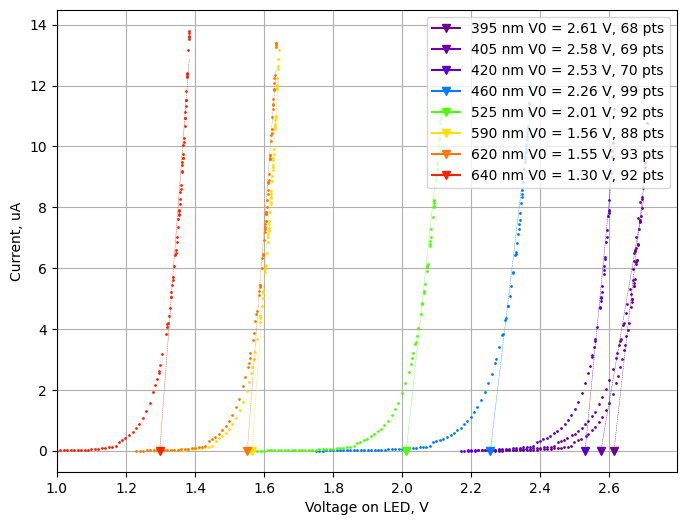

In [4]:
URL = 'https://raw.githubusercontent.com/evgeny-kolonsky/Lab4/refs/heads/main/PE/2026.11/DIY/'
I_FLOOR = 5e-9  # A, noise level is ~1 nA
SAT = 0.99      # fraction of max current: source limit, current saturates
V_TOL = 0.03    # V, outlier if V deviates from neighbours (dropouts, reconnections)

name = 'forward'
url = URL+ f'{name}.csv'
text = request.urlopen(url).read().decode('utf-8').splitlines()
WL, V, I, OVR, I0  = np.genfromtxt(text, \
                              delimiter=',', usecols=[1,6,7,9,14], skip_header=1, unpack=True)
# V is the measured voltage (not the set one): above ~3 uA the source cannot hold
# the set voltage, but (V_meas, I) still lie on the LED I-V curve
I = (I - I0) * 1e-9  # subtract current at 0 V, nA -> A

def clean_mask(V, I, OVR):
  ok = np.isfinite(I) & (OVR == 0)
  ok &= (I > I_FLOOR) & (I < SAT * np.max(I[ok]))
  # outliers: V vs running median of 9 neighbours, sorted by current
  idx = np.where(ok)[0]
  idx = idx[np.argsort(I[idx])]
  for k, j in enumerate(idx):
    nb = idx[max(0, k-4): k+5]
    if abs(V[j] - np.median(V[nb])) > V_TOL:
      ok[j] = False
  return ok

fig, ax = plt.subplots(figsize=(8,6))
data = '#wl V0\n'
for wl in np.unique(WL):
  Vw, Iw = V[WL == wl], I[WL == wl]
  mask = clean_mask(Vw, Iw, OVR[WL == wl])
  color = wavelength_to_color(wl)
  plt.plot(Vw[mask], Iw[mask]*1e6, '.', ms=2, color=color)
  V0, fit = find_root(Vw[mask], Iw[mask])
  plt.plot(V0, 0, color=color, marker='v', label=f'{wl:.0f} nm V0 = {V0:.2f} V, {np.sum(mask)} pts')
  vdense = np.linspace(V0, np.max(Vw[mask]), 100)
  idense = fit.intercept + fit.slope * vdense
  plt.plot(vdense, idense*1e6, color=color, linestyle='dashed', lw=0.3)
  freq = c/wl *1e9
  wl_observed, wl_observed_err = get_observed_by_nominal(wl)
  data += f'{wl:.0f} {V0:.3f} {wl_observed:.0f} {wl_observed_err:.0f}\n'

plt.legend()
plt.xlabel('Voltage on LED, V')
plt.ylabel('Current, uA')
plt.xlim(left=1)
plt.grid()

print(data)

# Planck

/tmp/ipykernel_1173/503868239.py:6: RuntimeWarning: divide by zero encountered in divide
  return c * h/ e / energy  * 1e9


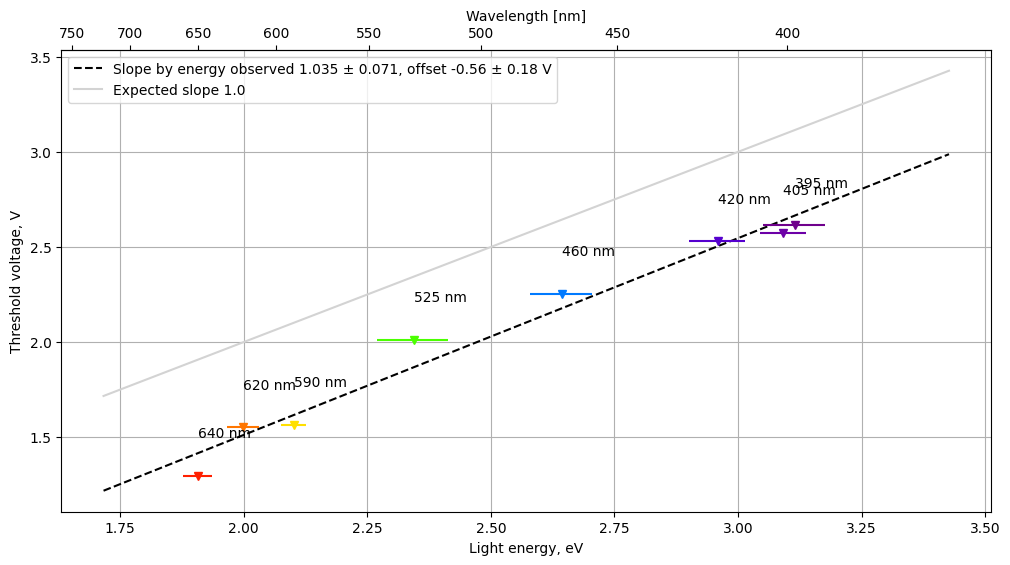

h/e = 4.279e-15 ± 2.9e-16 V s, accepted 4.1357e-15 V s
V0 - E per LED, V: [-0.5  -0.52 -0.43 -0.39 -0.33 -0.54 -0.45 -0.61]


In [5]:
def wl2E(wl):
    return c * h / e / (wl *1e-9)


def E2wl(energy):
    return c * h/ e / energy  * 1e9

fig, ax = plt.subplots(figsize=(12,6))


secax = ax.secondary_xaxis('top', functions=(wl2E, E2wl))
secax.set_xlabel('Wavelength [nm]')


wl_nominal, V0, wl_observed, wl_observed_err = np.genfromtxt(data.splitlines()).T


energy_top = h * c / (wl_observed - wl_observed_err) * 1e9 / e
energy_low = h * c / (wl_observed + wl_observed_err) * 1e9 / e
energy_observed  = h * c / wl_observed * 1e9 / e
energy_err = np.vstack((energy_top - energy_observed, energy_observed - energy_low))

energy_nominal = h * c / wl_nominal * 1e9 / e

energy_for_fit  = energy_observed
fit = linregress(energy_for_fit, V0)
slope = fit.slope
offset = fit.intercept
en_dense = np.linspace(np.min(energy_for_fit)*0.9, np.max(energy_for_fit)*1.1)
plt.plot(en_dense, en_dense * slope + offset, color='black', ls='--', \
         label=rf'Slope by energy observed {slope:.3f} ± {fit.stderr:.3f}, offset {offset:.2f} ± {fit.intercept_stderr:.2f} V')



for i in range(len(V0)):
  # Reshape energy_err[:, i] from (2,) to (2, 1) for asymmetric errors on a single point
  plt.errorbar(energy_observed[i], V0[i], yerr=0, xerr=energy_err[:, i].reshape((2, 1)), ls='', color=wavelength_to_color(wl_nominal[i]))
  plt.plot( energy_observed[i], V0[i], marker='v', color=wavelength_to_color(wl_nominal[i]))
  plt.annotate(f'{wl_nominal[i]:.0f} nm', (energy_observed[i], V0[i]+0.2))

plt.plot(en_dense, en_dense , color='lightgray', label=f'Expected slope 1.0')

#for i in range(len(V0)):
#    plt.annotate(f'{wl[i]*1e9:.0f} nm', (V0[i], energy[i]))

plt.grid()
plt.legend()
plt.xlabel(r'Light energy, eV')
plt.ylabel(r'Threshold voltage, V')
plt.legend()
plt.show()

print(f'h/e = {slope * h/e:.3e} ± {fit.stderr * h/e:.1e} V s, accepted {h/e:.4e} V s')
print('V0 - E per LED, V:', np.round(V0 - energy_observed, 2))